# ResolveAI — Student Grievance Classification & Priority Prediction
**NLP Lab (2311217L)** · Asawale Vedant Machindra · Kushwah Krishna Rohitkumar

This notebook contains **all NLP and machine-learning work** of the project, in the order it was done:
dataset → text extraction → cleaning → TF-IDF → classification & evaluation → sentiment → entity extraction → topic modelling → multilingual → generative AI & prompt engineering → export to the web app.

**How to run:** Colab → *Runtime → Run all*. Upload `complaints.csv` when asked (or keep it next to the notebook).
The last section writes `model.json`, `metrics.json` and `heldout.csv`. The deployed web app loads exactly these files, so the numbers you see here are the numbers in the app.

In [ ]:
%pip install -q vaderSentiment langdetect deep-translator pypdf reportlab

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import re, json, random, io, os, zipfile, textwrap
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (7, 3.4), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

# Find the dataset (or ask for an upload when running in Colab)
for p in ["complaints.csv", "data/complaints.csv", "backend/data/complaints.csv"]:
    if Path(p).exists(): DATA_PATH = Path(p); break
else:
    from google.colab import files
    DATA_PATH = Path(list(files.upload())[0])
OUT = Path("backend/artifacts") if Path("backend").exists() else Path("artifacts")   # where the app's files are written
OUT.mkdir(parents=True, exist_ok=True)
print("dataset:", DATA_PATH, "| outputs go to:", OUT)

## 1. Dataset
Open-source **SCOPE** project dataset (MIT-licensed repository): student complaints with a *category* and an *urgency* (we call it *priority* in the app).
> Honest note: the sentences are short and tidy and look machine-written, so scores here may be higher than on real student complaints.

In [ ]:
df = pd.read_csv(DATA_PATH)
print("rows, columns:", df.shape, "| nulls:", int(df.isna().sum().sum()), "| duplicate texts:", int(df.complaint_text.duplicated().sum()))
df.head(5)

rows, columns: (3000, 4) | nulls: 0 | duplicate texts: 0


,id,complaint_text,category,urgency
0,1,I'm having trouble registering for CHEM 102. T...,Academic,Medium
1,2,Just wanted to note that the lightbulb above t...,Facilities,Low
2,3,"There's been no hot water in Cedar Hall, wing ...",Housing,High
3,4,URGENT!! I am trying to take my midterm exam o...,IT Support,Critical
4,5,My financial aid package seems lower than expe...,Financial Aid,Medium


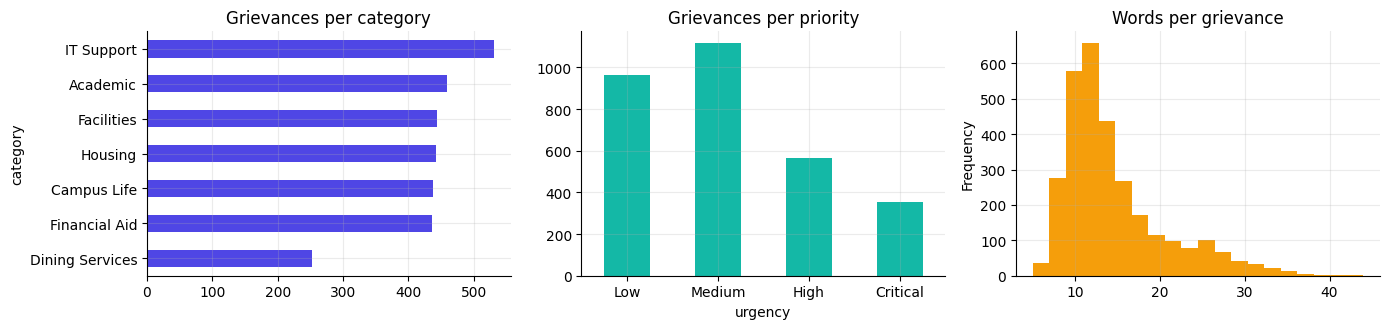

Average words per grievance: 14.3
Classes are not equal in size (Dining Services is smallest, Critical is the rarest priority) -> we use a stratified split and class weights.


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
df.category.value_counts().sort_values().plot.barh(ax=ax[0], color="#4F46E5", title="Grievances per category")
df.urgency.value_counts().reindex(["Low", "Medium", "High", "Critical"]).plot.bar(ax=ax[1], color="#14B8A6", title="Grievances per priority", rot=0)
df.complaint_text.str.split().str.len().plot.hist(ax=ax[2], bins=20, color="#F59E0B", title="Words per grievance")
plt.tight_layout(); plt.show()
print("Average words per grievance:", round(df.complaint_text.str.split().str.len().mean(), 1))
print("Classes are not equal in size (Dining Services is smallest, Critical is the rarest priority) -> we use a stratified split and class weights.")

## 2. Text extraction
Grievances can arrive as letters (TXT or PDF) or as a CSV. We extract the grievance text from each. The PDF below is created in the notebook, then read back with `pypdf`.

In [ ]:
from pypdf import PdfReader
from reportlab.lib.pagesizes import A4
from reportlab.pdfgen import canvas

def grievance_from_letter(text):
    """The grievance is the part after 'Grievance:'. If the marker is missing, use the whole text."""
    m = re.search(r"Grievance:\s*(.+?)(?:\n\s*Regards|\Z)", text, flags=re.S)
    return " ".join((m.group(1) if m else text).split())

letter = "To,\nThe Student Grievance Cell\n\nSubject: Grievance submission\n\nGrievance: There has been no hot water in Cedar Hall for three days.\n\nRegards,\nA Student\n"
Path("demo_inputs").mkdir(exist_ok=True)
Path("demo_inputs/letter.txt").write_text(letter)
c = canvas.Canvas("demo_inputs/letter.pdf", pagesize=A4); y = 800
for line in letter.splitlines(): c.drawString(60, y, line); y -= 18
c.save()

txt_text = Path("demo_inputs/letter.txt").read_text()
pdf_text = "\n".join(p.extract_text() or "" for p in PdfReader("demo_inputs/letter.pdf").pages)
print("TXT  ->", grievance_from_letter(txt_text))
print("PDF  ->", grievance_from_letter(pdf_text))
print("CSV  ->", pd.read_csv(DATA_PATH).complaint_text.iloc[0])

TXT  -> There has been no hot water in Cedar Hall for three days.
PDF  -> There has been no hot water in Cedar Hall for three days.
CSV  -> I'm having trouble registering for CHEM 102. The system says it's full, but it's a required course for my major and I need it this semester. Is there any chance of getting an override or joining a waitlist? Need help asap.


## 3. Text cleaning and preprocessing
Steps: lowercase → remove punctuation → split into words → remove stopwords → light stemming.
We **keep "not", "no", "never"** because *"not working"* and *"working"* mean opposite things. This exact code is also used by the web app.

In [ ]:
STOP = set(ENGLISH_STOP_WORDS) - {"not", "no", "never"}

def stem(w):
    """Very small suffix stemmer: ragging -> ragg, requests -> request."""
    if len(w) > 5 and w.endswith("ing"): return w[:-3]
    if len(w) > 4 and w.endswith("ed"): return w[:-2]
    if len(w) > 3 and w.endswith("s") and not w.endswith("ss"): return w[:-1]
    return w

def clean_steps(text):
    lower = text.lower()
    no_punct = " ".join(re.sub(r"[^a-z0-9\s]", " ", lower).split())
    tokens = no_punct.split()
    no_stop = [t for t in tokens if t not in STOP and len(t) > 1 and not t.isdigit()]
    stemmed = [stem(t) for t in no_stop]
    return {"original": text, "lowercase": lower, "no_punctuation": no_punct, "tokens": tokens,
            "no_stopwords": no_stop, "stemmed": stemmed, "cleaned": " ".join(stemmed)}

def clean(text): return clean_steps(text)["cleaned"]

for k, v in clean_steps("The 8:30 AM shuttle bus didn't show up at the South Campus stop, so students were late for CHEM 102!").items():
    print(f"{k:15}", v)

original        The 8:30 AM shuttle bus didn't show up at the South Campus stop, so students were late for CHEM 102!
lowercase       the 8:30 am shuttle bus didn't show up at the south campus stop, so students were late for chem 102!
no_punctuation  the 8 30 am shuttle bus didn t show up at the south campus stop so students were late for chem 102
tokens          ['the', '8', '30', 'am', 'shuttle', 'bus', 'didn', 't', 'show', 'up', 'at', 'the', 'south', 'campus', 'stop', 'so', 'students', 'were', 'late', 'for', 'chem', '102']
no_stopwords    ['shuttle', 'bus', 'didn', 'south', 'campus', 'stop', 'students', 'late', 'chem']
stemmed         ['shuttle', 'bus', 'didn', 'south', 'campu', 'stop', 'student', 'late', 'chem']
cleaned         shuttle bus didn south campu stop student late chem


In [ ]:
df["clean"] = df.complaint_text.map(clean)
raw_vocab = len(CountVectorizer(lowercase=True).fit(df.complaint_text).vocabulary_)
clean_vocab = len(CountVectorizer().fit(df.clean).vocabulary_)
print(f"Vocabulary before cleaning: {raw_vocab}  ->  after cleaning: {clean_vocab}")
df[["complaint_text", "clean"]].head(5)

Vocabulary before cleaning: 4032  ->  after cleaning: 2985


,complaint_text,clean
0,I'm having trouble registering for CHEM 102. T...,hav trouble register chem say requir course ma...
1,Just wanted to note that the lightbulb above t...,just want note lightbulb study carrel 4th floo...
2,"There's been no hot water in Cedar Hall, wing ...",no hot water cedar hall wing hour gett really ...
3,URGENT!! I am trying to take my midterm exam o...,urgent try midterm exam online psyc right exam...
4,My financial aid package seems lower than expe...,financial aid package lower expect year help u...


## 4. Train / validation / test split
70 % train (the model learns), 15 % validation (we choose the model), 15 % test (final check, **used only once**). Stratified so every part keeps the same class proportions; fixed seed for reproducibility.

In [ ]:
strat = df.category + "|" + df.urgency
train, rest = train_test_split(df, test_size=0.30, random_state=SEED, stratify=strat)
val, test = train_test_split(rest, test_size=0.50, random_state=SEED, stratify=rest.category + "|" + rest.urgency)
print("train / validation / test:", len(train), len(val), len(test))
pd.DataFrame({"train": train.urgency.value_counts(normalize=True), "val": val.urgency.value_counts(normalize=True), "test": test.urgency.value_counts(normalize=True)}).round(3)

train / validation / test: 2100 450 450


,train,val,test
urgency,,,
Medium,0.372,0.373,0.371
Low,0.321,0.320,0.322
High,0.189,0.189,0.187
Critical,0.118,0.118,0.120


## 5. Vectorization with TF-IDF
Each grievance becomes a list of numbers. A word scores high if it is **frequent in this grievance but rare in all grievances**. We use single words and word pairs (1–2-grams), ignore terms seen fewer than 2 times, and dampen repeats with `sublinear_tf`.

In [ ]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(train.clean)
X_train = tfidf.transform(train.clean); words = tfidf.get_feature_names_out()
print("matrix shape (grievances x features):", X_train.shape, "| non-zero share: %.2f%%" % (100 * X_train.nnz / np.prod(X_train.shape)))
top_words = {}
for c in sorted(train.category.unique()):
    m = np.asarray(X_train[(train.category == c).values].mean(axis=0)).ravel()
    top_words[c] = [words[i] for i in m.argsort()[-10:][::-1]]
pd.DataFrame({c: ", ".join(w[:7]) for c, w in top_words.items()}, index=["top TF-IDF words"]).T

matrix shape (grievances x features): (2100, 3533) | non-zero share: 0.32%


,top TF-IDF words
Academic,"professor, course, advisor, grade, grad, reque..."
Campus Life,"campu, campu need, need, student, event, cente..."
Dining Services,"din hall, din, hall, serv, hall serv, soup, food"
Facilities,"library, build, light, elevator, near, main, r..."
Financial Aid,"aid, financial, financial aid, need, loan, stu..."
Housing,"room, dorm, dorm room, roommate, ra, floor, hall"
IT Support,"university, online, access, unable, software, ..."


## 6. Classification and evaluation
We predict two things: **category** (7 classes) and **priority** (4 classes). Three standard text classifiers are trained on the training set and compared on the validation set:
Naive Bayes, Logistic Regression and Linear SVM. The best one (by validation F1) is tested **once** on the test set.

In [ ]:
def pipe(model): return Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)), ("model", model)])
CANDIDATES = {"Naive Bayes": lambda: MultinomialNB(alpha=0.3),
              "Logistic Regression": lambda: LogisticRegression(C=1, max_iter=3000, class_weight="balanced"),
              "Linear SVM": lambda: LinearSVC(C=0.3, class_weight="balanced")}

def scores(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="weighted", zero_division=0)
    return {"accuracy": round(accuracy_score(y, p), 3), "precision": round(float(pr), 3), "recall": round(float(rc), 3), "f1": round(float(f1), 3)}

def per_class(y, p, labels):
    pr, rc, f1, sup = precision_recall_fscore_support(y, p, labels=labels, zero_division=0)
    return {l: {"precision": round(float(pr[i]), 3), "recall": round(float(rc[i]), 3), "f1": round(float(f1[i]), 3), "support": int(sup[i])} for i, l in enumerate(labels)}

TARGETS = {"category": "category", "priority": "urgency"}     # app name -> dataset column
classification, final_models, comparison_tables = {}, {}, {}
for name, col in TARGETS.items():
    res = {}
    for mname, mk in CANDIDATES.items():
        p = pipe(mk()).fit(train.clean, train[col])
        res[mname] = {"train_acc": round(accuracy_score(train[col], p.predict(train.clean)), 3),
                      "val_acc": round(accuracy_score(val[col], p.predict(val.clean)), 3),
                      "val_f1": scores(val[col], p.predict(val.clean))["f1"]}
    comparison_tables[name] = res
    print(f"\n=== {name.upper()}: model comparison (train vs validation) ===")
    print(pd.DataFrame(res).T.assign(gap=lambda d: (d.train_acc - d.val_acc).round(3)))


=== CATEGORY: model comparison (train vs validation) ===
                     train_acc  val_acc  val_f1    gap
Naive Bayes              0.982    0.967   0.967  0.015
Logistic Regression      0.980    0.969   0.969  0.011
Linear SVM               0.990    0.971   0.971  0.019

=== PRIORITY: model comparison (train vs validation) ===
                     train_acc  val_acc  val_f1    gap
Naive Bayes              0.846    0.611   0.601  0.235
Logistic Regression      0.880    0.607   0.608  0.273
Linear SVM               0.926    0.602   0.602  0.324


### Overfitting and underfitting check
*Overfitting* = great on training data, poor on new data. *Underfitting* = the model is too simple for both.
In Logistic Regression, a **large C means weak regularisation** (the model can memorise); a **tiny C means strong regularisation** (too simple). We compare train and validation accuracy and pick the middle.

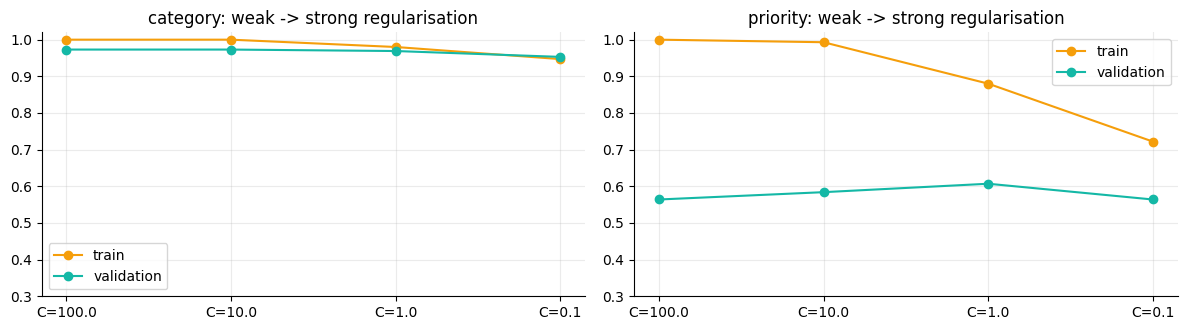

       C  train_acc  val_acc
0  100.0      1.000    0.564
1   10.0      0.993    0.584
2    1.0      0.880    0.607
3    0.1      0.722    0.564


In [ ]:
overfit = {}
for name, col in TARGETS.items():
    rows = []
    for C in [100, 10, 1, 0.1]:
        p = pipe(LogisticRegression(C=C, max_iter=3000, class_weight="balanced")).fit(train.clean, train[col])
        rows.append({"C": C, "train_acc": round(accuracy_score(train[col], p.predict(train.clean)), 3), "val_acc": round(accuracy_score(val[col], p.predict(val.clean)), 3)})
    overfit[name] = rows
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for a, (name, rows) in zip(ax, overfit.items()):
    d = pd.DataFrame(rows); x = np.arange(len(d))
    a.plot(x, d.train_acc, "o-", color="#F59E0B", label="train"); a.plot(x, d.val_acc, "o-", color="#14B8A6", label="validation")
    a.set_xticks(x); a.set_xticklabels([f"C={c}" for c in d.C]); a.set_title(f"{name}: weak -> strong regularisation"); a.set_ylim(0.3, 1.02); a.legend()
plt.tight_layout(); plt.show()
print(pd.DataFrame(overfit["priority"]))

### Final model and test-set results
The best model by validation F1 is retrained on the training data and tested **once** on the unseen test set. The *baseline* always guesses the most common class; a useful model must beat it.
- **Accuracy** – share of correct predictions · **Precision** – of the grievances predicted as X, how many really are X
- **Recall** – of the real X grievances, how many we found · **F1** – balance of precision and recall (weighted over classes)

In [ ]:
for name, col in TARGETS.items():
    res = comparison_tables[name]; best = max(res, key=lambda k: res[k]["val_f1"])
    final = pipe(CANDIDATES[best]()).fit(train.clean, train[col]); final_models[name] = final
    preds = final.predict(test.clean); labels = sorted(df[col].unique())
    base = DummyClassifier(strategy="most_frequent").fit(train.clean, train[col])
    classification[name] = {"models": res, "overfit_demo": overfit[name], "best": best,
        "baseline_acc": round(accuracy_score(test[col], base.predict(test.clean)), 3), "test": scores(test[col], preds), "labels": labels,
        "cm": confusion_matrix(test[col], preds, labels=labels).tolist(), "per_class": per_class(test[col], preds, labels)}
    print(f"{name.upper():9} best model: {best:20} test: {classification[name]['test']}   baseline accuracy: {classification[name]['baseline_acc']}")

CATEGORY  best model: Linear SVM           test: {'accuracy': 0.958, 'precision': 0.958, 'recall': 0.958, 'f1': 0.957}   baseline accuracy: 0.176
PRIORITY  best model: Logistic Regression  test: {'accuracy': 0.589, 'precision': 0.593, 'recall': 0.589, 'f1': 0.59}   baseline accuracy: 0.371


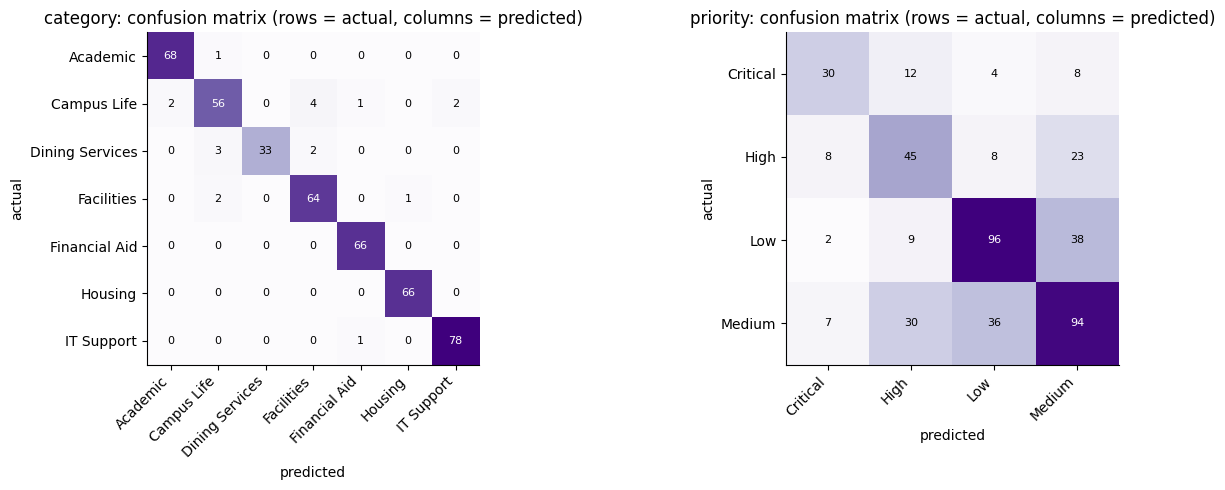

Per-class results for PRIORITY:


,precision,recall,f1,support
Critical,0.638,0.556,0.594,54.0
High,0.469,0.536,0.500,84.0
Low,0.667,0.662,0.664,145.0
Medium,0.577,0.563,0.570,167.0


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (name, d) in zip(ax, classification.items()):
    cm = np.array(d["cm"]); a.imshow(cm, cmap="Purples"); a.grid(False)
    a.set_xticks(range(len(d["labels"]))); a.set_xticklabels(d["labels"], rotation=45, ha="right"); a.set_yticks(range(len(d["labels"]))); a.set_yticklabels(d["labels"])
    for i in range(len(cm)):
        for j in range(len(cm)): a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
    a.set_title(f"{name}: confusion matrix (rows = actual, columns = predicted)"); a.set_xlabel("predicted"); a.set_ylabel("actual")
plt.tight_layout(); plt.show()
print("Per-class results for PRIORITY:"); pd.DataFrame(classification["priority"]["per_class"]).T

**Reading the results.** Category is easy (distinct topics) so accuracy is high. Priority is a *judgement*: similar sentences can get different urgency labels, so a much lower score than category is expected and honest. What matters is that it clearly beats the guessing baseline and that train and validation scores are close (no overfitting).

## 7. Sentiment analysis (VADER)
VADER is a **rule-based** tool: a dictionary of words with sentiment scores, no training needed. Compound score ≤ −0.05 = Negative, ≥ +0.05 = Positive, otherwise Neutral. We set "please" to 0 because it is politeness, not positivity.

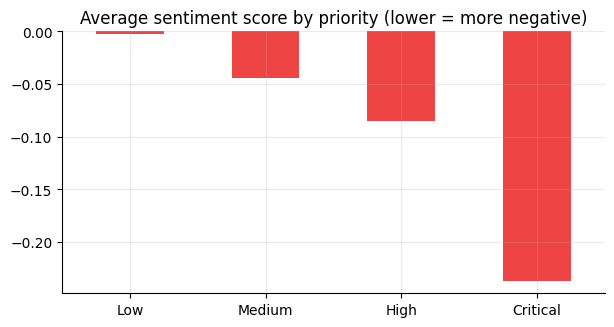

Sentiment share: {'Neutral': 0.466, 'Negative': 0.347, 'Positive': 0.188}


In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
_V = SentimentIntensityAnalyzer(); _V.lexicon.update({"please": 0})

def sentiment(text):
    s = _V.polarity_scores(text)["compound"]
    return ("Negative" if s <= -0.05 else "Positive" if s >= 0.05 else "Neutral"), round(s, 3)

df["sent_score"] = df.complaint_text.map(lambda t: sentiment(t)[1])
df["sent_label"] = df.sent_score.map(lambda s: "Negative" if s <= -0.05 else "Positive" if s >= 0.05 else "Neutral")
sentiment_by_priority = {u: round(float(g.sent_score.mean()), 3) for u, g in df.groupby("urgency")}
sentiment_share = {k: round(float(v), 3) for k, v in df.sent_label.value_counts(normalize=True).items()}
pd.Series(sentiment_by_priority).reindex(["Low", "Medium", "High", "Critical"]).plot.bar(color="#EF4444", rot=0, title="Average sentiment score by priority (lower = more negative)")
plt.show(); print("Sentiment share:", sentiment_share)

### Sentiment self-check (honest evaluation)
The dataset has **no sentiment labels**, so accuracy can only be measured on labels we give. Below are 20 random grievances with VADER's label. Fill `MY_LABELS` with your own judgement (`"Negative"`, `"Neutral"` or `"Positive"`, in the same order) and re-run the cell to get the agreement percentage.

In [ ]:
check = test.sample(20, random_state=1)[["complaint_text"]].copy()
check["VADER"] = check.complaint_text.map(lambda t: sentiment(t)[0])
MY_LABELS = []      # e.g. ["Negative", "Neutral", ...]  (20 items)
if len(MY_LABELS) == len(check):
    check["mine"] = MY_LABELS; print("Agreement with my labels: %.0f%%" % (100 * (check.VADER == check.mine).mean()))
else:
    print("Fill MY_LABELS with 20 labels to compute agreement.")
check.reset_index(drop=True)

Fill MY_LABELS with 20 labels to compute agreement.


,complaint_text,VADER
0,I need to request an extension for my final pa...,Negative
1,Need assistance understanding the difference b...,Neutral
2,Trying to access the online course materials f...,Neutral
3,The link to the required online textbook for m...,Negative
4,The inter-campus shuttle service schedule is i...,Negative
5,The dining hall labels for vegetarian/vegan it...,Neutral
6,The elevator in Davis Hall failed inspection a...,Negative
7,The online portal for course registration is c...,Negative
8,The elevator in the Administration building is...,Neutral
9,The campus needs more events focused on sustai...,Positive


## 8. Information extraction – named entities
We extract campus-specific entities with **regular-expression rules**: course codes (*CHEM 102*), buildings (*Cedar Hall*), times (*8:30 AM*) and days (*Monday*). Rules are light, fast and easy to explain; the app uses the same rules.

In [ ]:
_RULES = [
    ("COURSE", re.compile(r"\b[A-Z]{2,5}\s+\d{3}[A-Z]?\b")),
    ("BUILDING", re.compile(r"\b[A-Z][a-zA-Z]*(?:\s+[A-Z][a-zA-Z]*)*\s+(?:Hall|Library|Building|Center|Centre|Lab|Campus)\b")),
    ("TIME", re.compile(r"\b\d{1,2}(?::\d{2})?\s*(?:am|pm|AM|PM)\b")),
    ("DAY", re.compile(r"\b(?:Monday|Tuesday|Wednesday|Thursday|Friday|Saturday|Sunday|yesterday|today|tomorrow|Yesterday|Today|Tomorrow)\b")),
]
def extract_entities(text):
    found = [{"text": m.group(0), "label": l, "start": m.start(), "end": m.end()} for l, rx in _RULES for m in rx.finditer(text)]
    found.sort(key=lambda e: (e["start"], -e["end"])); out, last = [], -1
    for e in found:                               # drop overlapping matches
        if e["start"] >= last: out.append(e); last = e["end"]
    return out

def show(text):
    s, pos = "", 0
    for e in extract_entities(text): s += text[pos:e["start"]] + f"[{e['text']} | {e['label']}]"; pos = e["end"]
    return s + text[pos:]
for t in df.complaint_text[df.complaint_text.str.contains(r"\d{3}")].head(4): print(show(t))
ner_counts = Counter(e["label"] for t in df.complaint_text for e in extract_entities(t))
ner_counts = dict(sorted(ner_counts.items(), key=lambda x: -x[1])); print("\nEntities found in all 3000 grievances:", ner_counts)

I'm having trouble registering for [CHEM 102 | COURSE]. The system says it's full, but it's a required course for my major and I need it this semester. Is there any chance of getting an override or joining a waitlist? Need help asap.
URGENT!! I am trying to take my midterm exam online for [PSYC 210 | COURSE] right now and the exam portal just crashed. The exam is timed and I can't get back in. Please help immediately, I don't want to fail because of a technical issue!
Professor Miller hasn't posted grades for the midterm project in [ECON 305 | COURSE], which was submitted three weeks ago. It's hard to know where I stand in the course without this feedback.
The Wi-Fi connection in the basement lecture hall of the [Engineering Building | BUILDING] ([ENG 015 | COURSE]) is extremely weak and often drops. It makes it impossible to follow along with online resources during lectures.

Entities found in all 3000 grievances: {'COURSE': 265, 'BUILDING': 158, 'DAY': 49, 'TIME': 12}


## 9. Topic modelling (LDA)
LDA reads all grievances **without their labels** and groups words that appear together into *topics*. If the topics match the real categories, the data has real structure. We try 5, 7 and 10 topics. (Words appear in stemmed form.)

Topic 1 -> university, access, online, requir, email, class, software, unable
Topic 2 -> room, dorm, hall, build, floor, near, main, library
Topic 3 -> need, aid, financial, information, ra, loan, student, advisor
Topic 4 -> campu, need, student, service, option, center, event, study
Topic 5 -> din, hall, serv, request, food, today, staff, soup
Topic 6 -> roommate, light, room, student, park, library, consistently, account
Topic 7 -> professor, course, grad, provide, grade, registration, paper, lab


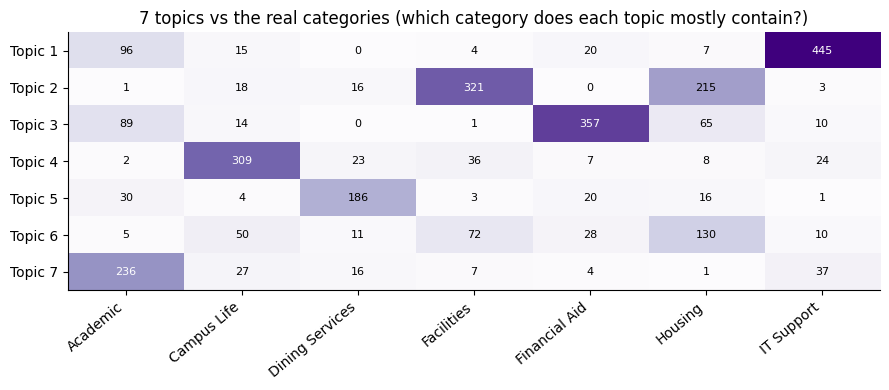

In [ ]:
cv = CountVectorizer(max_df=0.7, min_df=3); Xc = cv.fit_transform(df.clean); w = cv.get_feature_names_out()
topics = {}
for k in [5, 7, 10]:
    lda = LatentDirichletAllocation(n_components=k, random_state=SEED, learning_method="batch", max_iter=20).fit(Xc)
    tw = {f"Topic {i+1}": [w[j] for j in t.argsort()[-8:][::-1]] for i, t in enumerate(lda.components_)}
    ct = pd.crosstab(pd.Series(lda.transform(Xc).argmax(axis=1) + 1, name="topic"), df.category)
    topics[str(k)] = {"topics": tw, "crosstab": {"index": [f"Topic {i}" for i in ct.index], "columns": list(ct.columns), "values": ct.values.tolist()}, "perplexity": round(float(lda.perplexity(Xc)), 1)}
    if k == 7: ct7, tw7 = ct, tw
for n, ws in tw7.items(): print(n, "->", ", ".join(ws))
fig, a = plt.subplots(figsize=(9, 4)); a.imshow(ct7.values, cmap="Purples", aspect="auto"); a.grid(False)
a.set_xticks(range(len(ct7.columns))); a.set_xticklabels(ct7.columns, rotation=40, ha="right"); a.set_yticks(range(len(ct7))); a.set_yticklabels([f"Topic {i}" for i in ct7.index])
for i in range(ct7.shape[0]):
    for j in range(ct7.shape[1]): a.text(j, i, ct7.values[i, j], ha="center", va="center", fontsize=8, color="white" if ct7.values[i, j] > ct7.values.max() / 2 else "black")
a.set_title("7 topics vs the real categories (which category does each topic mostly contain?)"); plt.tight_layout(); plt.show()

## 10. Multilingual NLP: detect and translate
Grievances may arrive in Hindi or Marathi. We **detect the language** (`langdetect`) and **translate to English** so the same classifier can be used. Translation tries the free Google endpoint (`deep-translator`); an optional cloud cell below uses **AWS Translate / Comprehend**.
> Needs internet. If a cell prints "unavailable", re-run it in Colab.

In [ ]:
from langdetect import detect, DetectorFactory
from deep_translator import GoogleTranslator
DetectorFactory.seed = 0
EXAMPLES = [("मेरे हॉस्टल में तीन दिन से गर्म पानी नहीं आ रहा है।", "There has been no hot water in my hostel for three days."),
            ("कॉलेज का वाई-फाई बहुत धीमा है और बार-बार बंद हो जाता है।", "The college Wi-Fi is very slow and keeps disconnecting."),
            ("माझ्या शिष्यवृत्तीची रक्कम अजून खात्यात जमा झाली नाही.", "My scholarship amount has not yet been credited to my account."),
            ("मेसमध्ये जेवण थंड आणि खराब दर्जाचे दिले जात आहे.", "The mess is serving cold, poor quality food.")]
def to_english(text):
    try: lang = detect(text)
    except Exception: lang = "?"
    if lang == "en": return text, lang
    try: return GoogleTranslator(source="auto", target="en").translate(text), lang
    except Exception as e: return None, lang
rows = []
for src, ref in EXAMPLES:
    en, lang = to_english(src)
    rows.append({"language detected": lang, "original": src, "translation": en or "unavailable (no internet?)", "reference": ref})
pd.DataFrame(rows)

,language detected,original,translation,reference
0,hi,मेरे हॉस्टल में तीन दिन से गर्म पानी नहीं आ रह...,unavailable (no internet?),There has been no hot water in my hostel for t...
1,hi,कॉलेज का वाई-फाई बहुत धीमा है और बार-बार बंद ह...,unavailable (no internet?),The college Wi-Fi is very slow and keeps disco...
2,mr,माझ्या शिष्यवृत्तीची रक्कम अजून खात्यात जमा झा...,unavailable (no internet?),My scholarship amount has not yet been credite...
3,mr,मेसमध्ये जेवण थंड आणि खराब दर्जाचे दिले जात आहे.,unavailable (no internet?),"The mess is serving cold, poor quality food."


In [ ]:
# Classify the translations (or the English reference if translation was unavailable) with the trained models
for r in rows:
    text = r["translation"] if not r["translation"].startswith("unavailable") else r["reference"]
    c = clean(text); print(f"{final_models['category'].predict([c])[0]:16} | {final_models['priority'].predict([c])[0]:8} | {text}")

Housing          | High     | There has been no hot water in my hostel for three days.
IT Support       | Medium   | The college Wi-Fi is very slow and keeps disconnecting.
Financial Aid    | High     | My scholarship amount has not yet been credited to my account.
Dining Services  | Medium   | The mess is serving cold, poor quality food.


In [ ]:
# OPTIONAL cloud services: AWS Translate + Comprehend. Set USE_AWS = True and enter your credentials when asked.
USE_AWS = False
if USE_AWS:
    import boto3, getpass
    os.environ["AWS_ACCESS_KEY_ID"] = getpass.getpass("AWS access key id: "); os.environ["AWS_SECRET_ACCESS_KEY"] = getpass.getpass("AWS secret key: ")
    REGION = "ap-south-1"; translate = boto3.client("translate", region_name=REGION); comprehend = boto3.client("comprehend", region_name=REGION)
    for src, ref in EXAMPLES[:3]:
        lang = comprehend.detect_dominant_language(Text=src)["Languages"][0]["LanguageCode"]
        en = translate.translate_text(Text=src, SourceLanguageCode=lang, TargetLanguageCode="en")["TranslatedText"]
        sent = comprehend.detect_sentiment(Text=en, LanguageCode="en")["Sentiment"]
        ents = [(e["Text"], e["Type"]) for e in comprehend.detect_entities(Text=en, LanguageCode="en")["Entities"]]
        print(f"[{lang}] {en}\n   AWS sentiment: {sent} | VADER: {sentiment(en)[0]} | AWS entities: {ents}\n")
else:
    print("AWS cell skipped (USE_AWS = False).")

AWS cell skipped (USE_AWS = False).


## 11. Generative AI and prompt engineering
The trained models decide the **category and priority**. The LLM (Google Gemini) only **writes the response**: a summary, the office that should handle it, a next step and a polite reply.
We compare two prompts on the same grievances:
- **Prompt v1** – one plain sentence.
- **Prompt v2** – a role, our model's analysis as context, a strict JSON format, and rules (be empathetic, do not invent facts, do not promise outcomes, mention the response time).

In [ ]:
SLA = {"Critical": "within 24 hours", "High": "within 48 hours", "Medium": "within 5 working days", "Low": "within 10 working days"}
PROMPT_V1 = 'Write a reply to this student grievance: "{g}"'
PROMPT_V2 = """You are a university grievance-redressal assistant.
Student grievance: \"\"\"{g}\"\"\"
Our system's analysis -> category: {cat}; priority: {pri}; sentiment: {sen}; entities found: {ents}.
Return ONLY valid JSON with exactly these keys:
{{"summary": "max 20 words", "department": "office that should handle it", "action": "one concrete next step", "reply": "polite reply, exactly 3 sentences"}}
Rules: be empathetic; do not promise outcomes; do not invent facts that are not in the grievance; mention the response time '{sla}'."""
print(PROMPT_V1, "\n\n", PROMPT_V2)

Write a reply to this student grievance: "{g}" 

 You are a university grievance-redressal assistant.
Student grievance: """{g}"""
Our system's analysis -> category: {cat}; priority: {pri}; sentiment: {sen}; entities found: {ents}.
Return ONLY valid JSON with exactly these keys:
{{"summary": "max 20 words", "department": "office that should handle it", "action": "one concrete next step", "reply": "polite reply, exactly 3 sentences"}}
Rules: be empathetic; do not promise outcomes; do not invent facts that are not in the grievance; mention the response time '{sla}'.


In [ ]:
import requests
try:
    from google.colab import userdata; GEMINI_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    GEMINI_KEY = os.environ.get("GEMINI_API_KEY") or ""
MODELS = [m for m in [os.environ.get("GEMINI_MODEL"), "gemini-3.8-flash", "gemini-3.5-flash", "gemini-flash-latest"] if m]

def call_gemini(prompt, as_json=False):
    last = ""
    for m in dict.fromkeys(MODELS):
        try:
            r = requests.post(f"https://generativelanguage.googleapis.com/v1beta/models/{m}:generateContent", headers={"x-goog-api-key": GEMINI_KEY},
                              json={"contents": [{"parts": [{"text": prompt}]}], "generationConfig": ({"responseMimeType": "application/json"} if as_json else {})}, timeout=40).json()
            if "candidates" in r: return r["candidates"][0]["content"]["parts"][0]["text"]
            last = r.get("error", {}).get("message", "")[:120]
        except Exception as e: last = type(e).__name__
    raise RuntimeError(last)

if not GEMINI_KEY: print("No Gemini key found. In Colab: add a secret named GEMINI_API_KEY (left sidebar, key icon) and re-run. Skipping the live comparison.")
else:
    ok = 0
    for g in test.complaint_text.sample(3, random_state=7):
        c = clean(g); cat = final_models["category"].predict([c])[0]; pri = final_models["priority"].predict([c])[0]
        print("GRIEVANCE:", g, f"-> {cat} / {pri}")
        try: print("  v1:", call_gemini(PROMPT_V1.format(g=g)).strip()[:300].replace("\n", " "))
        except Exception as e: print("  v1 error:", e)
        try:
            out = json.loads(call_gemini(PROMPT_V2.format(g=g, cat=cat, pri=pri, sen=sentiment(g)[0], ents=[e["text"] for e in extract_entities(g)], sla=SLA[pri]), as_json=True))
            valid = all(k in out for k in ["summary", "department", "action", "reply"]); ok += valid; print("  v2:", out, "| valid JSON:", valid)
        except Exception as e: print("  v2 error:", e)
    print(f"\nPrompt v2 returned valid, parseable JSON for {ok}/3 grievances (v1 returns free text that a program cannot read reliably).")

GRIEVANCE: The elevator in Davis Hall is making a scraping noise. -> Facilities / Medium
  v1: Here are a few options for how to reply, depending on your role and the current status of the repair.   ### Option 1: Standard & Immediate Acknowledgment (Best Default) **Subject:** Re: Report regarding Davis Hall Elevator  Dear [Student Name],  Thank you for bringing this to our attention. We take 
  v2: {'summary': 'Report of a scraping noise coming from the elevator in Davis Hall.', 'department': 'Facilities Management', 'action': 'Dispatch a maintenance technician to inspect the Davis Hall elevator.', 'reply': 'Thank you for bringing the issue with the Davis Hall elevator to our attention. Your report has been forwarded to our Facilities Management team for an inspection. You can expect a follow-up response regarding this issue within 5 working days.'} | valid JSON: True
GRIEVANCE: The campus shuttle bus drivers seem poorly trained on the routes and schedules. -> Campus Life / Medium
  v1

## 12. Export to the web app
The deployed app does **not** need scikit-learn. We export the trained TF-IDF and linear models as plain numbers in `model.json` (`vocabulary`, `idf`, `coef`, `intercept`), and the app re-implements the small prediction formula with NumPy.
Below we prove the export is correct: the portable predictor must give the **same answers** as scikit-learn on every test grievance.

In [ ]:
def head(pipeline):
    clf = pipeline.named_steps["model"]
    coef, inter = (clf.feature_log_prob_, clf.class_log_prior_) if hasattr(clf, "feature_log_prob_") else (clf.coef_, clf.intercept_)
    assert coef.shape[0] == len(clf.classes_)
    return {"classes": [str(c) for c in clf.classes_], "kind": type(clf).__name__, "coef": np.round(coef, 5).tolist(), "intercept": np.round(inter, 5).tolist()}

tf_fit = final_models["category"].named_steps["tfidf"]
assert tf_fit.get_feature_names_out().tolist() == final_models["priority"].named_steps["tfidf"].get_feature_names_out().tolist()   # both models share one TF-IDF
model_json = {"version": 1, "stopwords": sorted(STOP),
              "tfidf": {"vocabulary": {t: int(i) for t, i in tf_fit.vocabulary_.items()}, "idf": np.round(tf_fit.idf_, 6).tolist()},
              "category": head(final_models["category"]), "priority": head(final_models["priority"])}

class PortableModel:
    """Exactly what the web app does at prediction time (NumPy only)."""
    def __init__(self, d):
        self.vocab = d["tfidf"]["vocabulary"]; self.idf = np.array(d["tfidf"]["idf"])
        self.heads = {k: (d[k]["classes"], np.array(d[k]["coef"]), np.array(d[k]["intercept"])) for k in ("category", "priority")}
    def vectorize(self, cleaned):
        toks = re.findall(r"(?u)\b\w\w+\b", cleaned)
        counts = {}
        for g in toks + [f"{a} {b}" for a, b in zip(toks, toks[1:])]:
            i = self.vocab.get(g)
            if i is not None: counts[i] = counts.get(i, 0) + 1
        if not counts: return np.array([], dtype=int), np.array([])
        idx = np.array(list(counts)); x = (1 + np.log(np.array([counts[i] for i in idx], float))) * self.idf[idx]
        return idx, x / np.linalg.norm(x)
    def proba(self, cleaned, target):
        classes, coef, inter = self.heads[target]; idx, x = self.vectorize(cleaned)
        s = coef[:, idx] @ x + inter; e = np.exp(s - s.max()); return dict(zip(classes, e / e.sum()))

pm = PortableModel(json.loads(json.dumps(model_json)))
for name, col in TARGETS.items():
    sk = final_models[name].predict(test.clean); mine = [max(pm.proba(c, name).items(), key=lambda kv: kv[1])[0] for c in test.clean]
    agree = np.mean(np.array(sk) == np.array(mine)); print(f"{name}: portable model agrees with scikit-learn on {agree*100:.2f}% of {len(test)} test grievances")
    assert agree >= 0.995

category: portable model agrees with scikit-learn on 100.00% of 450 test grievances
priority: portable model agrees with scikit-learn on 100.00% of 450 test grievances


In [ ]:
metrics = {"dataset": {"rows": len(df), "train": len(train), "val": len(val), "test": len(test), "avg_words": round(float(df.complaint_text.str.split().str.len().mean()), 1),
                       "category_counts": df.category.value_counts().to_dict(), "priority_counts": df.urgency.value_counts().to_dict(),
                       "vocab_raw": raw_vocab, "vocab_clean": clean_vocab, "tfidf_features": int(len(words)), "top_words": top_words},
           "category": classification["category"], "priority": classification["priority"],
           "sentiment_by_priority": sentiment_by_priority, "sentiment_share": sentiment_share,
           "ner_counts": ner_counts, "ner_engine": "domain regex rules (memory-optimised alternative to spaCy)", "topics": topics}
(OUT / "model.json").write_text(json.dumps(model_json, separators=(",", ":")))
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=1))
test[["id", "complaint_text", "category", "urgency"]].to_csv(OUT / "heldout.csv", index=False)     # unseen grievances the app uses for its self-checks
for f in ["model.json", "metrics.json", "heldout.csv"]: print(f"{f:14} {(OUT / f).stat().st_size / 1024:8.0f} KB")
with zipfile.ZipFile("artifacts.zip", "w") as z:
    for f in ["model.json", "metrics.json", "heldout.csv"]: z.write(OUT / f, f)
try:
    from google.colab import files; files.download("artifacts.zip")      # in Colab: downloads the 3 files for the app
except Exception: print("Saved artifacts.zip (copy the 3 files into backend/artifacts/ of the app).")

model.json          416 KB
metrics.json         11 KB
heldout.csv          48 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Summary

In [ ]:
summary = pd.DataFrame({t: {"best model": classification[t]["best"], "test accuracy": classification[t]["test"]["accuracy"], "precision": classification[t]["test"]["precision"],
                            "recall": classification[t]["test"]["recall"], "F1": classification[t]["test"]["f1"], "guessing baseline": classification[t]["baseline_acc"]} for t in classification}).T
display(summary)

,best model,test accuracy,precision,recall,F1,guessing baseline
category,Linear SVM,0.958,0.958,0.958,0.957,0.176
priority,Logistic Regression,0.589,0.593,0.589,0.59,0.371


**Limitations (be ready to say these):** the dataset looks machine-written; priority is a subjective label so about 60 % accuracy is realistic; sentiment accuracy is only measured on the labels you give in section 7; models are trained on English text (other languages are translated first); the LLM writes *drafts* that need human review.